# Minimum-Snap Motion Primitives, Collision Filtering & Scoring in JAX

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/arunkumar-singh/drone_course_repo/blob/main/tutorials/quadrotor_min_snap_primitives_jax_colab.ipynb)

A step-by-step, classroom-friendly JAX notebook implementing degree-7 minimum-snap motion primitives, vectorized trajectory sampling, obstacle collision filtering, and cost-based trajectory selection:

1. **Block 1 (Slides 16–17)**: Single-primitive coefficient solve via `M_inv = jnp.linalg.inv(M)` and evaluation of $(t, p, v, a, j)$ on a 1D moving-state example.
2. **Block 2 (`jax.vmap`)**: Reusing the exact same solver and evaluator over sampled $(x_f, v_f)$ targets with randomly sampled durations $T$ chosen via the straight-line speed heuristic $\bar{v}_k = \|\mathbf{x}_{f,k} - \mathbf{p}_0\|_2 / T_k \in [0.5, 1.0]\,\text{m/s}$.
3. **Block 3 (Collision Filtering)**: Writing a single-trajectory obstacle clearance checker first, then using `jax.vmap` to filter out colliding trajectories against inflated circular obstacles.
4. **Block 4 (Scoring & Selection)**: Implementing the multi-term score $C_k = w_g \|\mathbf{p}_k(T_k) - \mathbf{p}_{\text{goal}}\|_2^2 + w_s J_4[\mathbf{p}_k] + w_T T_k$ and selecting the lowest-cost collision-free trajectory.


In [1]:
import importlib.util
import subprocess
import sys

_missing = []
try:
    import jax
    import jax.numpy as jnp
except ImportError:
    _missing.append("jax")

if importlib.util.find_spec("matplotlib") is None:
    _missing.append("matplotlib")

if _missing:
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", *_missing])

import jax
import jax.numpy as jnp
import matplotlib.pyplot as plt

# Preserve full float32 precision on CUDA GPUs (disable TF32 10-bit matmul rounding)
jax.config.update("jax_default_matmul_precision", "highest")

plt.rcParams.update({
    "figure.dpi": 120,
    "axes.grid": True,
    "grid.alpha": 0.25,
    "grid.linestyle": "--",
    "axes.titlesize": 11,
    "axes.titleweight": "bold",
    "axes.labelsize": 10,
    "legend.fontsize": 8.5,
})

print(f"JAX version: {jax.__version__}")
print(f"Backend:     {jax.default_backend()}")
print(f"Devices:     {jax.devices()}")


JAX version: 0.6.2


Backend:     gpu
Devices:     [CudaDevice(id=0)]


---
## Block 1: Slide 16–17 Single Minimum-Snap Primitive

In normalized time $u = t / T \in [0, 1]$, a degree-7 minimum-snap polynomial splits into the known initial-motion cubic $g(u)$ and four unknown higher-order terms:

$$
g(u) = x_0 + T v_0 u + \tfrac{1}{2} T^2 a_0 u^2 + \tfrac{1}{6} T^3 j_0 u^3,
\qquad
q(u) = g(u) + b_4 u^4 + b_5 u^5 + b_6 u^6 + b_7 u^7.
$$

Enforcing the terminal state $(x_f, v_f, a_f, j_f)$ at $u = 1$ yields the **final residuals** (Slide 16):

$$
\begin{aligned}
\rho_0 &= x_f - x_0 - T v_0 - \tfrac{1}{2} T^2 a_0 - \tfrac{1}{6} T^3 j_0, \\
\rho_1 &= T v_f - T v_0 - T^2 a_0 - \tfrac{1}{2} T^3 j_0, \\
\rho_2 &= T^2 a_f - T^2 a_0 - T^3 j_0, \\
\rho_3 &= T^3 j_f - T^3 j_0.
\end{aligned}
$$

Evaluating the derivatives of $b_4 u^4 + b_5 u^5 + b_6 u^6 + b_7 u^7$ at $u = 1$ gives the constant $4 \times 4$ system (Slide 17), solved once with `M_inv = jnp.linalg.inv(M)`:

$$
\underbrace{\begin{bmatrix}
1 & 1 & 1 & 1 \\
4 & 5 & 6 & 7 \\
12 & 20 & 30 & 42 \\
24 & 60 & 120 & 210
\end{bmatrix}}_{M}
\begin{bmatrix} b_4 \\ b_5 \\ b_6 \\ b_7 \end{bmatrix}
=
\begin{bmatrix} \rho_0 \\ \rho_1 \\ \rho_2 \\ \rho_3 \end{bmatrix}
\quad\Longrightarrow\quad
\begin{bmatrix} b_4 \\ b_5 \\ b_6 \\ b_7 \end{bmatrix}
= M^{-1} \rho.
$$

Physical derivatives follow from the chain rule $x^{(\ell)}(t) = T^{-\ell} q^{(\ell)}(u)$. Because `M_inv` multiplies along axis `0`, the exact same `solve_min_snap` and `eval_primitive` work unchanged for 1D scalars (`(8,)`) and $D$-dimensional vectors (`(8, D)`).


In [2]:
M = jnp.array([
    [1.0, 1.0, 1.0, 1.0],
    [4.0, 5.0, 6.0, 7.0],
    [12.0, 20.0, 30.0, 42.0],
    [24.0, 60.0, 120.0, 210.0],
])
M_inv = jnp.linalg.inv(M)


def solve_min_snap(x0, v0, a0, j0, xf, vf, af, jf, T):
    b0123 = jnp.array([x0, T * v0, 0.5 * T**2 * a0, (1.0 / 6.0) * T**3 * j0])
    rho = jnp.array([
        xf - x0 - T * v0 - 0.5 * T**2 * a0 - (1.0 / 6.0) * T**3 * j0,
        T * vf - T * v0 - T**2 * a0 - 0.5 * T**3 * j0,
        T**2 * af - T**2 * a0 - T**3 * j0,
        T**3 * jf - T**3 * j0,
    ])
    b4567 = M_inv @ rho
    return jnp.concatenate([b0123, b4567], axis=0)


def eval_primitive(coeffs, T, u):
    z, o = jnp.zeros_like(u), jnp.ones_like(u)
    Up = jnp.stack([o, u, u**2, u**3, u**4, u**5, u**6, u**7], axis=-1)
    Uv = jnp.stack([z, o, 2 * u, 3 * u**2, 4 * u**3, 5 * u**4, 6 * u**5, 7 * u**6], axis=-1) / T
    Ua = jnp.stack([z, z, 2 * o, 6 * u, 12 * u**2, 20 * u**3, 30 * u**4, 42 * u**5], axis=-1) / T**2
    Uj = jnp.stack([z, z, z, 6 * o, 24 * u, 60 * u**2, 120 * u**3, 210 * u**4], axis=-1) / T**3
    return T * u, Up @ coeffs, Uv @ coeffs, Ua @ coeffs, Uj @ coeffs


coeffs shape: (8,)
t = 0.0 s -> p=0.000000, v=0.300000, a=0.200000, j=-0.300000


t = 2.0 s -> p=2.500000, v=0.500031, a=0.000244, j=0.000122


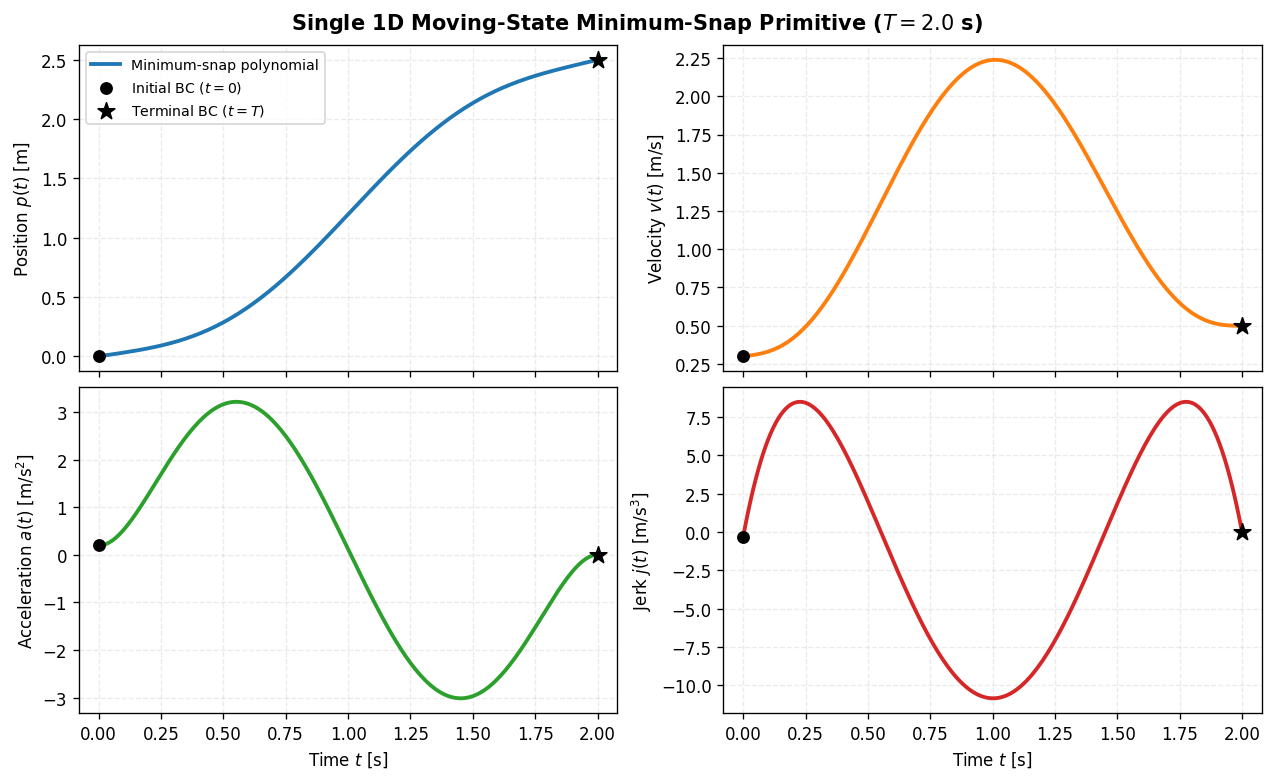

In [3]:
x0, v0, a0, j0 = 0.0, 0.3, 0.2, -0.3
xf, vf, af, jf = 2.5, 0.5, 0.0, 0.0
T = 2.0

coeffs = solve_min_snap(x0, v0, a0, j0, xf, vf, af, jf, T)
u = jnp.linspace(0.0, 1.0, 201)
t, p, v, a, j = eval_primitive(coeffs, T, u)

print(f"coeffs shape: {coeffs.shape}")
print(f"t = 0.0 s -> p={float(p[0]):.6f}, v={float(v[0]):.6f}, a={float(a[0]):.6f}, j={float(j[0]):.6f}")
print(f"t = {T:.1f} s -> p={float(p[-1]):.6f}, v={float(v[-1]):.6f}, a={float(a[-1]):.6f}, j={float(j[-1]):.6f}")

fig, axes = plt.subplots(2, 2, figsize=(10.5, 6.4), sharex=True, constrained_layout=True)
series = [
    (p, "Position $p(t)$ [m]", x0, xf, "#1f77b4"),
    (v, "Velocity $v(t)$ [m/s]", v0, vf, "#ff7f0e"),
    (a, "Acceleration $a(t)$ [m/s$^2$]", a0, af, "#2ca02c"),
    (j, "Jerk $j(t)$ [m/s$^3$]", j0, jf, "#d62728"),
]

for idx, (ax, (y, ylabel, y0_val, yf_val, color)) in enumerate(zip(axes.flat, series)):
    ax.plot(t, y, color=color, lw=2.3, label="Minimum-snap polynomial")
    ax.scatter([0.0], [y0_val], color="black", s=45, zorder=5, label="Initial BC ($t=0$)")
    ax.scatter([T], [yf_val], color="black", marker="*", s=110, zorder=5, label="Terminal BC ($t=T$)")
    ax.set_ylabel(ylabel)
    ax.set_xlim(-0.08, T + 0.08)
    if idx == 0:
        ax.legend(loc="upper left", frameon=True)

axes[1, 0].set_xlabel("Time $t$ [s]")
axes[1, 1].set_xlabel("Time $t$ [s]")
fig.suptitle("Single 1D Moving-State Minimum-Snap Primitive ($T = 2.0$ s)", fontsize=12.5, fontweight="bold")
plt.show()


---
## Block 2: Batch Sampling with `jax.vmap` over $(x_f, v_f, T)$

Without changing a single line of `solve_min_snap` or `eval_primitive`, `jax.vmap` maps them across a batch of $B$ sampled terminal states and durations:

```python
batch_solve = jax.jit(jax.vmap(solve_min_snap, in_axes=(None, None, None, None, 0, 0, None, None, 0)))
batch_eval  = jax.jit(jax.vmap(eval_primitive, in_axes=(0, 0, None)))
```

- First we sample the 34 terminal positions `xf_samples` $(x_f, y_f)$ and velocities `vf_samples` around the goal direction (Slide 19: 11 angles in $[-75^\circ, +75^\circ] \times 3$ distances $\{1.5, 2.0, 2.5\}\,\text{m}$, plus 1 goal-stop state).
- Next, using the sampled $(x_f, y_f)$ displacement $d_k = \|\mathbf{x}_{f,k} - \mathbf{p}_0\|_2$ as a speed heuristic, we randomly sample durations $T_k$ so that the heuristic average speed lies in $[0.5, 1.0]\,\text{m/s}$:

$$\bar{v}_k \sim \mathcal{U}(0.5,\ 1.0)\,\text{m/s}, \qquad T_k = \frac{\|\mathbf{x}_{f,k} - \mathbf{p}_0\|_2}{\bar{v}_k} \in [d_k,\ 2 d_k].$$

- Finally, `batch_solve` and `batch_eval` evaluate all 34 primitives in parallel over `(xf_samples, vf_samples, T_samples)`.


--- Random Heuristic Duration Sampling (34 candidates) ---
Inputs  -> xf_samples: (34, 2), vf_samples: (34, 2), T_samples: (34,)
Outputs -> coeffs_batch: (34, 8, 2), p_batch: (34, 101, 2), v_batch: (34, 101, 2)
Heuristic speed ||xf - p0|| / T range: [0.513, 0.993] m/s
Sampled duration T range:              [1.511, 8.414] s


Actual curve speed ||v(t)|| (33 fan):  [0.192, 1.605] m/s


Max terminal error -> pos: 3.81e-05, vel: 3.93e-05, acc: 1.42e-04, jerk: 2.13e-04


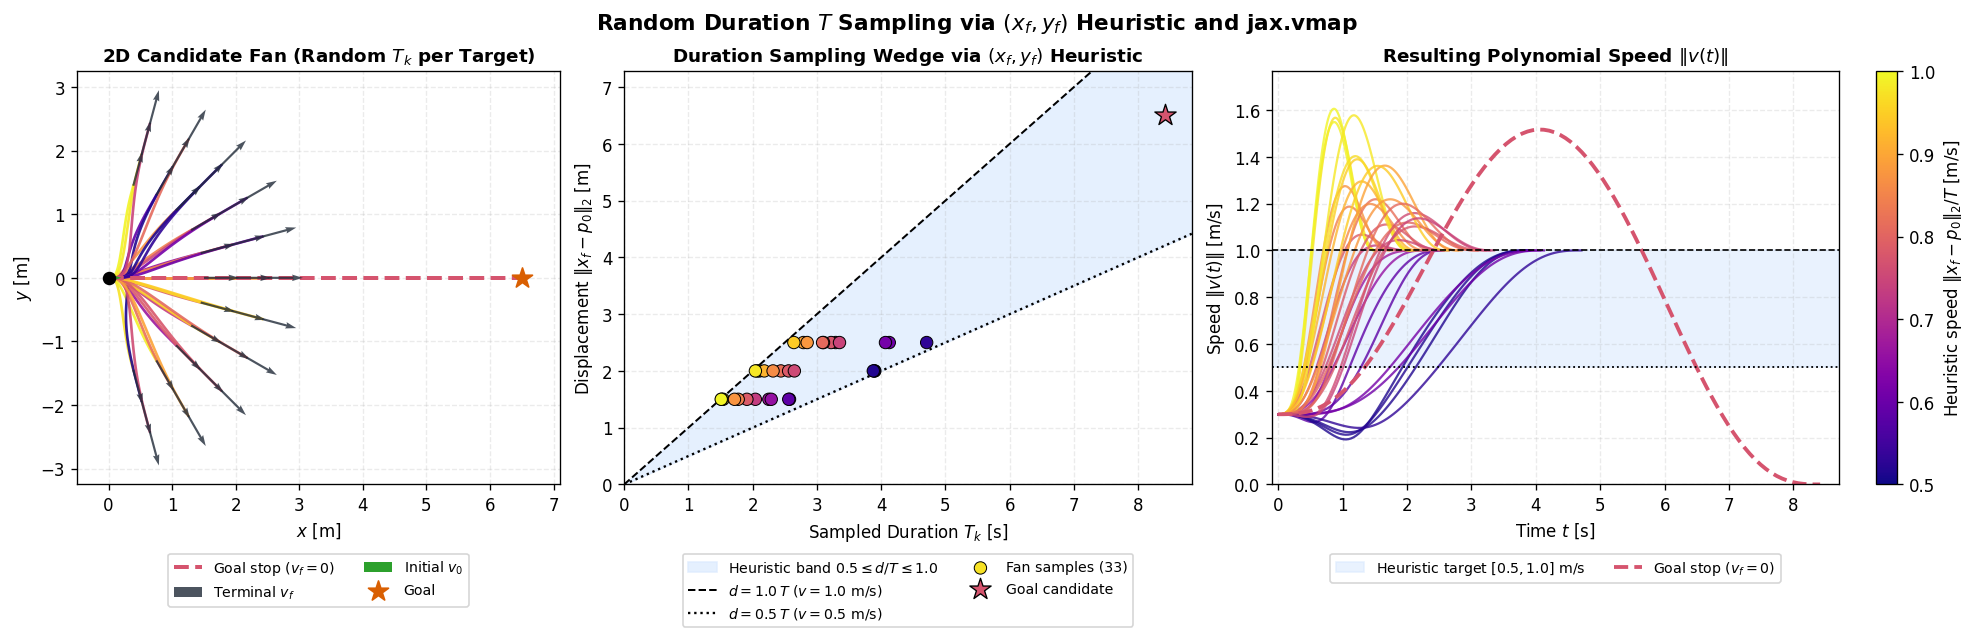

In [4]:
batch_solve = jax.jit(jax.vmap(solve_min_snap, in_axes=(None, None, None, None, 0, 0, None, None, 0)))
batch_eval = jax.jit(jax.vmap(eval_primitive, in_axes=(0, 0, None)))

p0 = jnp.array([0.0, 0.0])
v0 = jnp.array([0.3, 0.0])
a0 = jnp.array([0.0, 0.0])
j0 = jnp.array([0.0, 0.0])
af = jnp.array([0.0, 0.0])
jf = jnp.array([0.0, 0.0])
u_grid = jnp.linspace(0.0, 1.0, 101)

# 1) Sample terminal (xf, vf) targets (Slide 19: 33 fan targets + 1 goal stop)
goal = jnp.array([6.5, 0.0])
theta_goal = jnp.arctan2(goal[1] - p0[1], goal[0] - p0[0])
angles = jnp.deg2rad(jnp.linspace(-75.0, 75.0, 11))
dists = jnp.array([1.5, 2.0, 2.5])
dist_grid, ang_grid = jnp.meshgrid(dists, angles, indexing="ij")
phi = theta_goal + ang_grid.reshape(-1)
dirs = jnp.stack([jnp.cos(phi), jnp.sin(phi)], axis=-1)

xf_samples = jnp.concatenate([p0 + dist_grid.reshape(-1, 1) * dirs, goal[None, :]], axis=0)
vf_samples = jnp.concatenate([1.0 * dirs, jnp.zeros((1, 2))], axis=0)

# 2) Randomly sample T using ||xf - p0|| as heuristic so ||xf - p0|| / T in [0.5, 1.0] m/s
key = jax.random.PRNGKey(0)
disp = jnp.linalg.norm(xf_samples - p0, axis=-1)
v_heur = jax.random.uniform(key, shape=disp.shape, minval=0.5, maxval=1.0)
T_samples = disp / v_heur

# 3) Vectorized Slide 17 solve + trajectory evaluation over (xf, vf, T)
coeffs_batch = batch_solve(p0, v0, a0, j0, xf_samples, vf_samples, af, jf, T_samples)
t_batch, p_batch, v_batch, a_batch, j_batch = batch_eval(coeffs_batch, T_samples, u_grid)
speed_batch = jnp.linalg.norm(v_batch, axis=-1)
v_heur_check = disp / T_samples

print("--- Random Heuristic Duration Sampling (34 candidates) ---")
print(f"Inputs  -> xf_samples: {xf_samples.shape}, vf_samples: {vf_samples.shape}, T_samples: {T_samples.shape}")
print(f"Outputs -> coeffs_batch: {coeffs_batch.shape}, p_batch: {p_batch.shape}, v_batch: {v_batch.shape}")
print(f"Heuristic speed ||xf - p0|| / T range: [{float(v_heur_check.min()):.3f}, {float(v_heur_check.max()):.3f}] m/s")
print(f"Sampled duration T range:              [{float(T_samples.min()):.3f}, {float(T_samples.max()):.3f}] s")
print(f"Actual curve speed ||v(t)|| (33 fan):  [{float(speed_batch[:33].min()):.3f}, {float(speed_batch[:33].max()):.3f}] m/s")
print(
    f"Max terminal error -> pos: {float(jnp.max(jnp.abs(p_batch[:, -1] - xf_samples))):.2e}, "
    f"vel: {float(jnp.max(jnp.abs(v_batch[:, -1] - vf_samples))):.2e}, "
    f"acc: {float(jnp.max(jnp.abs(a_batch[:, -1] - af))):.2e}, "
    f"jerk: {float(jnp.max(jnp.abs(j_batch[:, -1] - jf))):.2e}"
)

# Clean 1x3 visualization tied together by heuristic speed v_heur in [0.5, 1.0] m/s
cmap = plt.cm.plasma
norm = plt.Normalize(vmin=0.5, vmax=1.0)

fig, (ax0, ax1, ax2) = plt.subplots(1, 3, figsize=(16.5, 5.2), constrained_layout=True)

# Panel 1: 2D trajectories colored by heuristic speed (i.e., sampled T)
for k in range(33):
    ax0.plot(p_batch[k, :, 0], p_batch[k, :, 1], color=cmap(norm(float(v_heur[k]))), lw=1.6, alpha=0.9)
ax0.plot(p_batch[33, :, 0], p_batch[33, :, 1], color=cmap(norm(float(v_heur[33]))), lw=2.4, ls="--", label="Goal stop ($v_f=0$)")
ax0.quiver(
    xf_samples[:33, 0], xf_samples[:33, 1],
    vf_samples[:33, 0], vf_samples[:33, 1],
    angles="xy", scale_units="xy", scale=1.8, width=0.0045,
    color="#1f2937", alpha=0.8, zorder=5, label="Terminal $v_f$",
)
ax0.quiver(
    [p0[0]], [p0[1]], [v0[0]], [v0[1]],
    angles="xy", scale_units="xy", scale=1.5, width=0.007,
    color="#2ca02c", zorder=6, label="Initial $v_0$",
)
ax0.scatter([p0[0]], [p0[1]], color="black", s=50, zorder=7)
ax0.scatter([goal[0]], [goal[1]], color="#d95f02", marker="*", s=160, zorder=7, label="Goal")
ax0.set_aspect("equal", adjustable="box")
ax0.set_xlim(-0.5, 7.1)
ax0.set_ylim(-3.25, 3.25)
ax0.set_xlabel("$x$ [m]")
ax0.set_ylabel("$y$ [m]")
ax0.set_title("2D Candidate Fan (Random $T_k$ per Target)")
ax0.legend(loc="upper center", bbox_to_anchor=(0.5, -0.15), ncol=2, frameon=True)

# Panel 2: Sampled T vs ||xf - p0|| inside the [0.5, 1.0] m/s speed wedge
T_line = jnp.linspace(0.0, float(T_samples.max()) * 1.05, 100)
ax1.fill_between(T_line, 0.5 * T_line, 1.0 * T_line, color="#dbeafe", alpha=0.7, label=r"Heuristic band $0.5 \leq d/T \leq 1.0$")
ax1.plot(T_line, 1.0 * T_line, "k--", lw=1.2, label=r"$d = 1.0\,T$ ($v=1.0$ m/s)")
ax1.plot(T_line, 0.5 * T_line, "k:", lw=1.4, label=r"$d = 0.5\,T$ ($v=0.5$ m/s)")
sc = ax1.scatter(T_samples[:33], disp[:33], c=v_heur[:33], cmap=cmap, norm=norm, s=55, edgecolors="black", linewidths=0.6, zorder=5, label="Fan samples (33)")
ax1.scatter([T_samples[33]], [disp[33]], c=[v_heur[33]], cmap=cmap, norm=norm, marker="*", s=180, edgecolors="black", linewidths=0.8, zorder=6, label="Goal candidate")
ax1.set_xlim(0.0, float(T_samples.max()) * 1.05)
ax1.set_ylim(0.0, float(disp.max()) * 1.12)
ax1.set_xlabel("Sampled Duration $T_k$ [s]")
ax1.set_ylabel(r"Displacement $\|x_f - p_0\|_2$ [m]")
ax1.set_title("Duration Sampling Wedge via $(x_f, y_f)$ Heuristic")
ax1.legend(loc="upper center", bbox_to_anchor=(0.5, -0.15), ncol=2, frameon=True)

# Panel 3: Actual speed ||v(t)|| along each primitive vs time t
ax2.axhspan(0.5, 1.0, color="#dbeafe", alpha=0.6, label="Heuristic target $[0.5, 1.0]$ m/s")
for k in range(33):
    ax2.plot(t_batch[k], speed_batch[k], color=cmap(norm(float(v_heur[k]))), lw=1.35, alpha=0.8)
ax2.plot(t_batch[33], speed_batch[33], color=cmap(norm(float(v_heur[33]))), lw=2.3, ls="--", label="Goal stop ($v_f=0$)")
ax2.axhline(1.0, color="black", ls="--", lw=1.0)
ax2.axhline(0.5, color="black", ls=":", lw=1.1)
ax2.set_xlim(-0.1, float(T_samples.max()) + 0.3)
ax2.set_ylim(0.0, float(speed_batch.max()) * 1.1)
ax2.set_xlabel("Time $t$ [s]")
ax2.set_ylabel(r"Speed $\|v(t)\|$ [m/s]")
ax2.set_title(r"Resulting Polynomial Speed $\|v(t)\|$")
ax2.legend(loc="upper center", bbox_to_anchor=(0.5, -0.15), ncol=2, frameon=True)

cbar = fig.colorbar(sc, ax=[ax0, ax1, ax2], location="right", fraction=0.018, pad=0.02)
cbar.set_label(r"Heuristic speed $\|x_f - p_0\|_2 / T$ [m/s]")

fig.suptitle("Random Duration $T$ Sampling via $(x_f, y_f)$ Heuristic and jax.vmap", fontsize=13, fontweight="bold")
plt.show()


---
## Block 3: Collision Filtering of Candidate Trajectories (Slide 21–22)

Before comparing how "good" any trajectory is, we must reject candidates that hit obstacles.

For a drone of radius $r_{\text{drone}}$ with safety buffer $\delta_{\text{safety}}$ and circular obstacle $m$ centered at $\mathbf{c}_m$ with radius $r_{\text{obs}, m}$, we define the **inflated exclusion radius**:

$$r_{\text{excl}, m} = r_{\text{obs}, m} + r_{\text{drone}} + \delta_{\text{safety}}.$$

A candidate trajectory $\mathbf{p}_k(t)$ sampled at discrete times $\{t_0, \dots, t_{N-1}\}$ is **collision-free** if every sampled point clears every obstacle's exclusion circle:

$$\min_{i,\,m} \Big(\|\mathbf{p}_k(t_i) - \mathbf{c}_m\|_2 - r_{\text{excl}, m}\Big) \geq 0.$$

To keep the code easy to follow, we write `check_single_trajectory_collision` for **one trajectory** first, and then call `jax.vmap` to check all 34 candidates in `p_batch` in parallel.


--- Block 3: Collision Filtering Summary ---
Obstacles: 2 | Exclusion radii r_excl: [0.75, 0.6] m
Total candidates: 34 | Collision-free: 23 | Colliding: 11

Colliding candidates (0-based index):
  Candidate # 3: min clearance margin = -0.2455 m (< 0 -> REJECTED)
  Candidate # 4: min clearance margin = -0.1417 m (< 0 -> REJECTED)
  Candidate #14: min clearance margin = -0.4680 m (< 0 -> REJECTED)
  Candidate #15: min clearance margin = -0.2540 m (< 0 -> REJECTED)
  Candidate #16: min clearance margin = -0.0500 m (< 0 -> REJECTED)
  Candidate #24: min clearance margin = -0.0154 m (< 0 -> REJECTED)
  Candidate #25: min clearance margin = -0.4751 m (< 0 -> REJECTED)
  Candidate #26: min clearance margin = -0.2485 m (< 0 -> REJECTED)
  Candidate #27: min clearance margin = -0.5500 m (< 0 -> REJECTED)
  Candidate #28: min clearance margin = -0.0429 m (< 0 -> REJECTED)


  Candidate #33: min clearance margin = -0.7243 m (< 0 -> REJECTED)


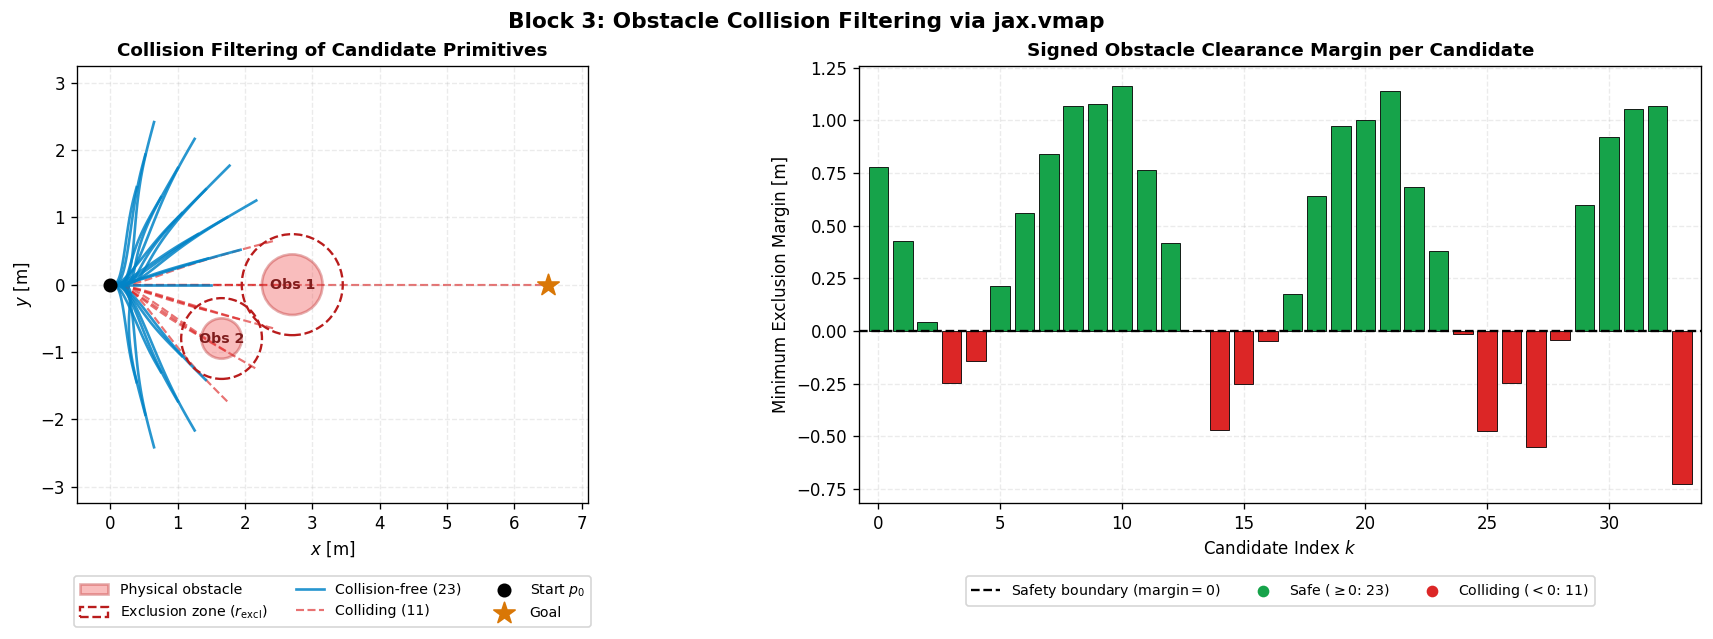

In [5]:
# Define two circular 2D obstacles in the workspace
# Obstacle 1 matches Slide 22 directly ahead; Obstacle 2 blocks part of the lower fan
obs_centers = jnp.array([
    [2.70,  0.00],  # Obstacle 1: directly in front of the drone (Slide 22)
    [1.65, -0.80],  # Obstacle 2: blocks the lower-right detour
])
obs_radii = jnp.array([0.45, 0.30])
r_drone = 0.15
safety_margin = 0.15
r_excl = obs_radii + r_drone + safety_margin  # [0.75, 0.60] m


def check_single_trajectory_collision(p_traj, obs_centers, r_excl):
    # p_traj has shape (N_pts, 2), obs_centers has shape (M_obs, 2)
    # Step 1: Vector from every obstacle center to every point along the curve -> (N_pts, M_obs, 2)
    diff = p_traj[:, None, :] - obs_centers[None, :, :]

    # Step 2: Euclidean distance from every trajectory point to every obstacle center -> (N_pts, M_obs)
    distances = jnp.linalg.norm(diff, axis=-1)

    # Step 3: Signed clearance margin outside each obstacle's inflated exclusion circle -> (N_pts, M_obs)
    # Positive means safe (outside r_excl); negative means inside the exclusion zone (collision)
    clearance_margins = distances - r_excl[None, :]

    # Step 4: Minimum clearance along the entire curve across all obstacles (scalar)
    min_margin = jnp.min(clearance_margins)

    # Step 5: Trajectory is collision-free if and only if every point clears every obstacle
    is_safe = min_margin >= 0.0
    return is_safe, min_margin


# Apply the single-trajectory check across all 34 candidates in p_batch using jax.vmap
batch_collision_check = jax.vmap(check_single_trajectory_collision, in_axes=(0, None, None))
is_safe_batch, min_margins = batch_collision_check(p_batch, obs_centers, r_excl)

num_total = int(p_batch.shape[0])
num_safe = int(jnp.sum(is_safe_batch))
num_colliding = num_total - num_safe

print("--- Block 3: Collision Filtering Summary ---")
print(f"Obstacles: {obs_centers.shape[0]} | Exclusion radii r_excl: {[round(float(r), 2) for r in r_excl]} m")
print(f"Total candidates: {num_total} | Collision-free: {num_safe} | Colliding: {num_colliding}")
print("\nColliding candidates (0-based index):")
for k in range(num_total):
    if not bool(is_safe_batch[k]):
        print(f"  Candidate #{k:2d}: min clearance margin = {float(min_margins[k]):+.4f} m (< 0 -> REJECTED)")

# Visualization: Left = Safe vs Colliding 2D trajectories, Right = Clearance margins
fig, (ax0, ax1) = plt.subplots(1, 2, figsize=(15.0, 5.2), constrained_layout=True)

# Draw obstacles and inflated exclusion zones
for m in range(obs_centers.shape[0]):
    cx, cy = float(obs_centers[m, 0]), float(obs_centers[m, 1])
    lbl_obs = "Physical obstacle" if m == 0 else None
    lbl_excl = r"Exclusion zone ($r_{\mathrm{excl}}$)" if m == 0 else None
    ax0.add_patch(plt.Circle((cx, cy), float(obs_radii[m]), color="#ef4444", alpha=0.35, ec="#b91c1c", lw=1.6, label=lbl_obs, zorder=3))
    ax0.add_patch(plt.Circle((cx, cy), float(r_excl[m]), fill=False, ls="--", ec="#b91c1c", lw=1.4, label=lbl_excl, zorder=3))
    ax0.text(cx, cy, f"Obs {m + 1}", ha="center", va="center", fontsize=8.5, fontweight="bold", color="#7f1d1d", zorder=4)

safe_labeled = False
coll_labeled = False
for k in range(num_total):
    if bool(is_safe_batch[k]):
        lbl = f"Collision-free ({num_safe})" if not safe_labeled else None
        safe_labeled = True
        ax0.plot(p_batch[k, :, 0], p_batch[k, :, 1], color="#0284c7", lw=1.6, alpha=0.85, label=lbl, zorder=2)
    else:
        lbl = f"Colliding ({num_colliding})" if not coll_labeled else None
        coll_labeled = True
        ax0.plot(p_batch[k, :, 0], p_batch[k, :, 1], color="#dc2626", lw=1.3, ls="--", alpha=0.65, label=lbl, zorder=1)

ax0.scatter([float(p0[0])], [float(p0[1])], color="black", s=55, zorder=6, label="Start $p_0$")
ax0.scatter([float(goal[0])], [float(goal[1])], color="#d97706", marker="*", s=180, zorder=6, label="Goal")
ax0.set_aspect("equal", adjustable="box")
ax0.set_xlim(-0.5, 7.1)
ax0.set_ylim(-3.25, 3.25)
ax0.set_xlabel("$x$ [m]")
ax0.set_ylabel("$y$ [m]")
ax0.set_title("Collision Filtering of Candidate Primitives")
ax0.legend(loc="upper center", bbox_to_anchor=(0.5, -0.15), ncol=3, frameon=True)

# Right panel: clearance margin bar chart
indices = jnp.arange(num_total)
bar_colors = ["#16a34a" if bool(s) else "#dc2626" for s in is_safe_batch]
ax1.bar(indices, min_margins, color=bar_colors, edgecolor="black", linewidth=0.5, zorder=3)
ax1.axhline(0.0, color="black", ls="--", lw=1.4, label=r"Safety boundary ($\mathrm{margin} = 0$)", zorder=4)
ax1.scatter([], [], color="#16a34a", label=f"Safe ($\\geq 0$: {num_safe})")
ax1.scatter([], [], color="#dc2626", label=f"Colliding ($< 0$: {num_colliding})")
ax1.set_xlim(-0.8, num_total - 0.2)
ax1.set_xlabel("Candidate Index $k$")
ax1.set_ylabel("Minimum Exclusion Margin [m]")
ax1.set_title("Signed Obstacle Clearance Margin per Candidate")
ax1.legend(loc="upper center", bbox_to_anchor=(0.5, -0.15), ncol=3, frameon=True)

fig.suptitle("Block 3: Obstacle Collision Filtering via jax.vmap", fontsize=13, fontweight="bold")
plt.show()


---
## Block 4: Scoring Function & Least-Cost Trajectory Selection (Slides 23–24 & 34)

Among all **collision-free** trajectories from Block 3, we pick the winner by minimizing the lecture's weighted planning cost (Slide 23):

$$C_k = \underbrace{w_g \left\|\mathbf{p}_k(T_k) - \mathbf{p}_{\text{goal}}\right\|_2^2}_{\text{Goal distance cost}} + \underbrace{w_s J_4[\mathbf{p}_k]}_{\text{Smoothness (snap) cost}} + \underbrace{w_T T_k}_{\text{Duration penalty}}.$$

- **Goal cost**: squared distance from the primitive endpoint $\mathbf{p}_k(T_k)$ to $\mathbf{p}_{\text{goal}}$ (pulls the drone toward the goal).
- **Smoothness cost $J_4[\mathbf{p}_k]$**: integrated squared snap $\int_0^{T_k} \|\mathbf{p}_k^{(4)}(t)\|_2^2\,dt$ (proportional to quadrotor angular acceleration / torque effort, Slide 4). Using Slide 34's exact polynomial formula on coefficients $\mathbf{b}_{4:7} = [b_4, b_5, b_6, b_7]^\top$:

$$J_4 = \frac{1}{T_k^7}\left(\mathbf{b}_x^\top Q_4 \mathbf{b}_x + \mathbf{b}_y^\top Q_4 \mathbf{b}_y\right), \qquad (Q_4)_{ij} = \frac{f_i f_j}{i + j + 1}, \quad f = [24, 120, 360, 840].$$

- **Duration penalty $w_T T_k$**: penalizes slow trajectories when $T_k$ varies across candidates (as sampled in Block 2).

To guarantee an unsafe trajectory is never chosen, we mask colliding candidates to $+\infty$ via `jnp.where(is_safe_batch, total_costs, jnp.inf)` before calling `jnp.argmin`.


--- Block 4: Top-5 Collision-Free Candidates ---
  Cand |   Dist |   Angle |  T [s] |    Goal |   Snap |   Time |   Total
--------------------------------------------------------------------------
#17 * |  2.00m |  +15.0° |   2.32 |  21.136 |  0.079 |  1.159 |  22.374
#29   |  2.50m |  +30.0° |   4.07 |  20.354 |  0.001 |  2.034 |  22.389
#18   |  2.00m |  +30.0° |   2.65 |  23.733 |  0.020 |  1.325 |  25.078
# 5   |  1.50m |   +0.0° |   2.57 |  25.000 |  0.007 |  1.287 |  26.294
# 6   |  1.50m |  +15.0° |   2.29 |  25.665 |  0.008 |  1.145 |  26.818



Selected least-cost safe trajectory: Candidate #17 | p_end = (1.932, 0.518) m | v_end = (0.966, 0.259) m/s | min clearance = 0.176 m


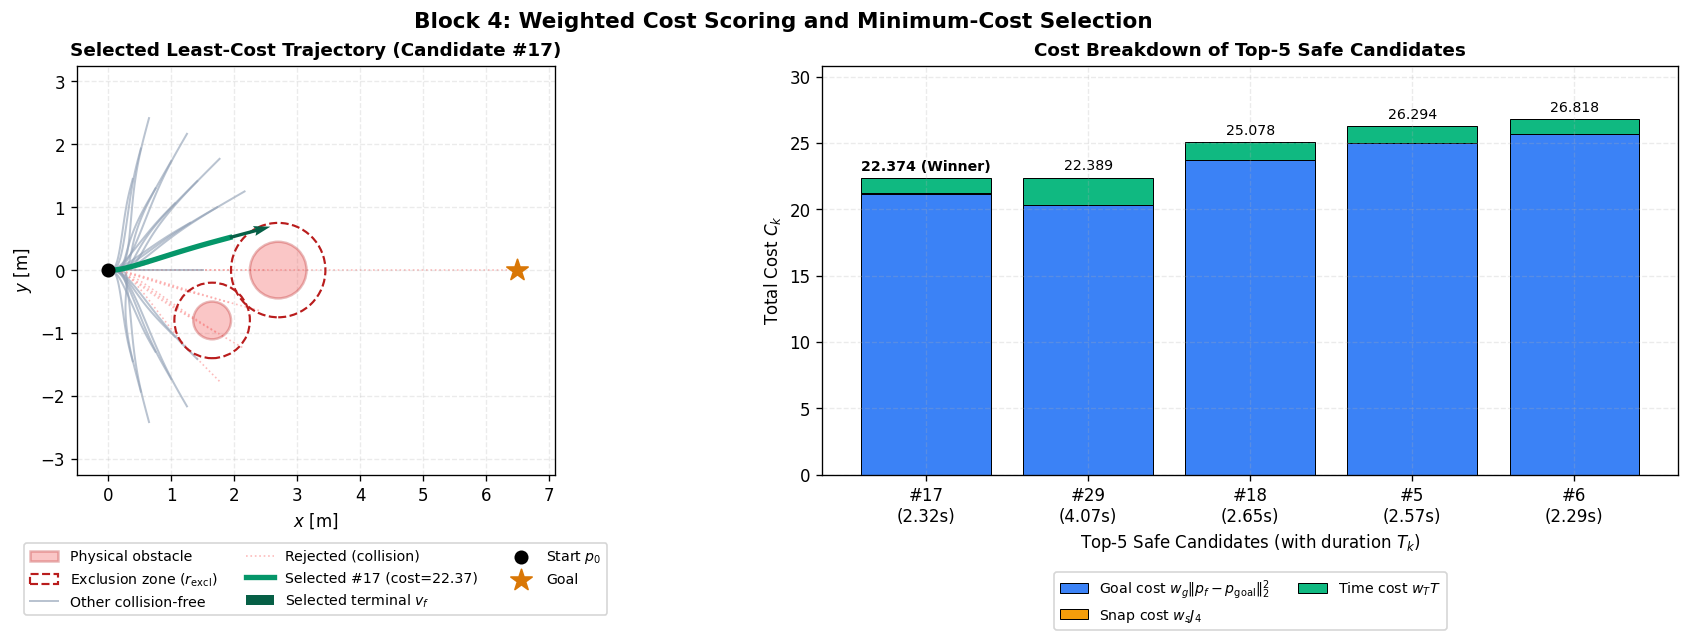

In [6]:
# Exact Slide 34 quadratic matrix Q4 for degree-7 snap coefficients [b4, b5, b6, b7]
# Fourth derivatives of u^4, u^5, u^6, u^7 have factorial scales f = [24, 120, 360, 840]
Q4 = jnp.array([
    [ 24.0 *  24.0 / 1.0,  24.0 * 120.0 / 2.0,  24.0 * 360.0 / 3.0,  24.0 * 840.0 / 4.0],
    [120.0 *  24.0 / 2.0, 120.0 * 120.0 / 3.0, 120.0 * 360.0 / 4.0, 120.0 * 840.0 / 5.0],
    [360.0 *  24.0 / 3.0, 360.0 * 120.0 / 4.0, 360.0 * 360.0 / 5.0, 360.0 * 840.0 / 6.0],
    [840.0 *  24.0 / 4.0, 840.0 * 120.0 / 5.0, 840.0 * 360.0 / 6.0, 840.0 * 840.0 / 7.0],
])


def compute_snap_cost(coeffs, T):
    # Extract the higher-order coefficients [b4, b5, b6, b7] for x and y
    b_x = coeffs[4:8, 0]
    b_y = coeffs[4:8, 1]

    # Exact integral of ||p^(4)(t)||^2 dt over [0, T] (Slide 34)
    j4_x = (b_x @ Q4 @ b_x) / (T ** 7)
    j4_y = (b_y @ Q4 @ b_y) / (T ** 7)
    return j4_x + j4_y


def score_single_trajectory(coeffs, p_traj, T, goal, w_g, w_s, w_T):
    # Step 1: Endpoint progress cost (how far the end of this primitive is from the goal)
    p_end = p_traj[-1]
    goal_cost = w_g * jnp.sum((p_end - goal) ** 2)

    # Step 2: Smoothness cost using exact integrated squared snap J4
    j4_val = compute_snap_cost(coeffs, T)
    snap_cost = w_s * j4_val

    # Step 3: Duration penalty (prefers faster trajectories when T varies)
    time_cost = w_T * T

    # Step 4: Total weighted candidate cost
    total_cost = goal_cost + snap_cost + time_cost
    return total_cost, goal_cost, snap_cost, time_cost, j4_val


# Score weights: Slide 23 goal & snap weights + duration penalty for Block 2's random T
w_g = 1.0
w_s = 1.0 / 1000.0
w_T = 0.5

# Evaluate score components across all 34 candidates via jax.vmap
batch_score = jax.vmap(score_single_trajectory, in_axes=(0, 0, 0, None, None, None, None))
total_costs, goal_costs, snap_costs, time_costs, j4_vals = batch_score(
    coeffs_batch, p_batch, T_samples, goal, w_g, w_s, w_T
)

# Filter out colliding trajectories by setting their cost to +infinity, then select minimum
feasible_costs = jnp.where(is_safe_batch, total_costs, jnp.inf)
best_idx = int(jnp.argmin(feasible_costs))

# Print ranked table of Top-5 collision-free candidates
ranked_indices = [int(k) for k in jnp.argsort(feasible_costs) if bool(is_safe_batch[int(k)])]
print("--- Block 4: Top-5 Collision-Free Candidates ---")
print(f"{'Cand':>6s} | {'Dist':>6s} | {'Angle':>7s} | {'T [s]':>6s} | {'Goal':>7s} | {'Snap':>6s} | {'Time':>6s} | {'Total':>7s}")
print("-" * 74)
for rank, k in enumerate(ranked_indices[:5]):
    mark = "*" if rank == 0 else " "
    ang_deg = float(jnp.rad2deg(phi[k])) if k < 33 else 0.0
    print(
        f"#{k:2d}{mark:>2s} | {float(disp[k]):5.2f}m | {ang_deg:+6.1f}° | {float(T_samples[k]):6.2f} | "
        f"{float(goal_costs[k]):7.3f} | {float(snap_costs[k]):6.3f} | {float(time_costs[k]):6.3f} | {float(total_costs[k]):7.3f}"
    )

print(
    f"\nSelected least-cost safe trajectory: Candidate #{best_idx} "
    f"| p_end = ({float(p_batch[best_idx, -1, 0]):.3f}, {float(p_batch[best_idx, -1, 1]):.3f}) m "
    f"| v_end = ({float(v_batch[best_idx, -1, 0]):.3f}, {float(v_batch[best_idx, -1, 1]):.3f}) m/s "
    f"| min clearance = {float(min_margins[best_idx]):.3f} m"
)

# Visualization: Left = Selected least-cost trajectory in XY map, Right = Top-5 cost breakdown
fig, (ax0, ax1) = plt.subplots(1, 2, figsize=(15.0, 5.2), constrained_layout=True)

for m in range(obs_centers.shape[0]):
    cx, cy = float(obs_centers[m, 0]), float(obs_centers[m, 1])
    lbl_obs = "Physical obstacle" if m == 0 else None
    lbl_excl = r"Exclusion zone ($r_{\mathrm{excl}}$)" if m == 0 else None
    ax0.add_patch(plt.Circle((cx, cy), float(obs_radii[m]), color="#ef4444", alpha=0.30, ec="#b91c1c", lw=1.5, label=lbl_obs, zorder=3))
    ax0.add_patch(plt.Circle((cx, cy), float(r_excl[m]), fill=False, ls="--", ec="#b91c1c", lw=1.3, label=lbl_excl, zorder=3))

coll_lbl, safe_lbl = False, False
for k in range(num_total):
    if k == best_idx:
        continue
    if bool(is_safe_batch[k]):
        lbl = "Other collision-free" if not safe_lbl else None
        safe_lbl = True
        ax0.plot(p_batch[k, :, 0], p_batch[k, :, 1], color="#94a3b8", lw=1.2, alpha=0.65, label=lbl, zorder=1)
    else:
        lbl = "Rejected (collision)" if not coll_lbl else None
        coll_lbl = True
        ax0.plot(p_batch[k, :, 0], p_batch[k, :, 1], color="#fca5a5", lw=1.0, ls=":", alpha=0.75, label=lbl, zorder=0)

ax0.plot(
    p_batch[best_idx, :, 0], p_batch[best_idx, :, 1],
    color="#059669", lw=3.2, label=f"Selected #{best_idx} (cost={float(total_costs[best_idx]):.2f})", zorder=5,
)
ax0.quiver(
    [float(p_batch[best_idx, -1, 0])], [float(p_batch[best_idx, -1, 1])],
    [float(v_batch[best_idx, -1, 0])], [float(v_batch[best_idx, -1, 1])],
    angles="xy", scale_units="xy", scale=1.5, width=0.007,
    color="#065f46", zorder=6, label="Selected terminal $v_f$",
)
ax0.scatter([float(p0[0])], [float(p0[1])], color="black", s=55, zorder=7, label="Start $p_0$")
ax0.scatter([float(goal[0])], [float(goal[1])], color="#d97706", marker="*", s=180, zorder=7, label="Goal")
ax0.set_aspect("equal", adjustable="box")
ax0.set_xlim(-0.5, 7.1)
ax0.set_ylim(-3.25, 3.25)
ax0.set_xlabel("$x$ [m]")
ax0.set_ylabel("$y$ [m]")
ax0.set_title(f"Selected Least-Cost Trajectory (Candidate #{best_idx})")
ax0.legend(loc="upper center", bbox_to_anchor=(0.5, -0.15), ncol=3, frameon=True)

# Right panel: stacked bar chart of Top-5 collision-free candidates
top5 = ranked_indices[:5]
x_pos = jnp.arange(len(top5))
g_top5 = jnp.array([float(goal_costs[k]) for k in top5])
s_top5 = jnp.array([float(snap_costs[k]) for k in top5])
t_top5 = jnp.array([float(time_costs[k]) for k in top5])
tot_top5 = g_top5 + s_top5 + t_top5

ax1.bar(x_pos, g_top5, color="#3b82f6", edgecolor="black", linewidth=0.6, label="Goal cost $w_g \\|p_f - p_{\\mathrm{goal}}\\|_2^2$")
ax1.bar(x_pos, s_top5, bottom=g_top5, color="#f59e0b", edgecolor="black", linewidth=0.6, label="Snap cost $w_s J_4$")
ax1.bar(x_pos, t_top5, bottom=g_top5 + s_top5, color="#10b981", edgecolor="black", linewidth=0.6, label="Time cost $w_T T$")

for i, k in enumerate(top5):
    tag = " (Winner)" if i == 0 else ""
    ax1.text(i, float(tot_top5[i]) + 0.35, f"{float(tot_top5[i]):.3f}{tag}", ha="center", va="bottom", fontsize=8.5, fontweight="bold" if i == 0 else "normal")

ax1.set_xticks(x_pos, [f"#{k}\n({float(T_samples[k]):.2f}s)" for k in top5])
ax1.set_ylim(0.0, float(jnp.max(tot_top5)) * 1.15)
ax1.set_xlabel("Top-5 Safe Candidates (with duration $T_k$)")
ax1.set_ylabel("Total Cost $C_k$")
ax1.set_title("Cost Breakdown of Top-5 Safe Candidates")
ax1.legend(loc="upper center", bbox_to_anchor=(0.5, -0.22), ncol=2, frameon=True)

fig.suptitle("Block 4: Weighted Cost Scoring and Minimum-Cost Selection", fontsize=13, fontweight="bold")
plt.show()
